In [3]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

# Download and load the EuroSAT dataset (RGB version)
dataset = datasets.EuroSAT(
    root="../data/raw/EuroSAT",
    transform=transform,
    download=True,
)

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [8]:
generator = torch.Generator().manual_seed(0)
train_set, val_set, test_set = torch.utils.data.random_split(
    dataset, [.8, .1, .1], generator = generator)


In [9]:
# create data loader for training data
stats_dataloader = DataLoader(train_set, batch_size = 512, shuffle = False)

We want to transform the data by normalising it. To this end, we first compute its mean and standard deviation

In [10]:
s = torch.zeros(3, dtype=torch.float64)
s2 = torch.zeros(3, dtype=torch.float64)
N = 0
for batch, label in stats_dataloader:
    batch = batch.double()
    s += batch.sum(dim = (0, 2, 3))    # batch has shape [512, 3, 64, 64] : [images, channels, height, width]
    s2 += (batch ** 2).sum(dim = (0, 2, 3))
    N += batch.shape[0] * batch.shape[2] * batch.shape[3]

mean = s / N
stdv = (s2 / N - mean ** 2) ** .5

print("mean:", mean)
print("stdv:", stdv)

mean: tensor([0.3433, 0.3797, 0.4075], dtype=torch.float64)
stdv: tensor([0.2017, 0.1364, 0.1152], dtype=torch.float64)


Define the normalisation transform for the dataset. This will not change the images themselves, but rather transform them whenever they are requested from the dataset.

In [11]:
dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), stdv.tolist())
])

In [12]:
train_dataloader = DataLoader(train_set, batch_size = 64, shuffle = True)
val_dataloader = DataLoader(val_set, batch_size = 64, shuffle = False)
test_dataloader = DataLoader(test_set, batch_size = 64, shuffle = False)

Plot some images from the training set

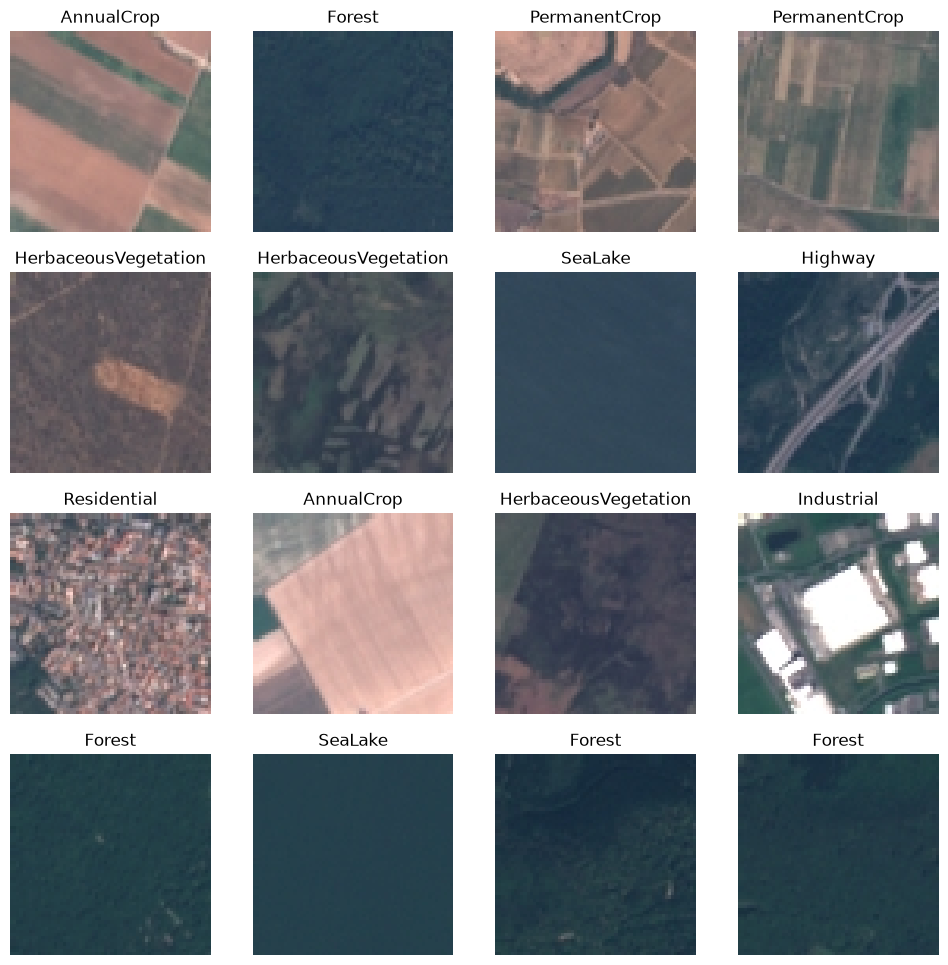

In [13]:
mean_t = mean.float().view(3, 1, 1)
std_t  = stdv.float().view(3, 1, 1)


figure = plt.figure(figsize=(12, 12))
cols, rows = 4, 4
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(train_set), size=(1,)).item()
    img, label = train_set[sample_idx]
    img = (img * std_t + mean_t).clamp(0, 1)

    # torch and matplotlib have different channel orders, so permute the image tensor
    img = img.permute(1, 2, 0)
    figure.add_subplot(rows, cols, i)
    plt.title(dataset.classes[label])
    plt.axis("off")
    plt.imshow(img)  

plt.show()

### Define the CNN model

EuroSAT land-cover classes are defined by local spatial patterns. We will thus use a CNN, which keeps the pixel neighbourhood and learns these patterns with shared filters while far fewer parameters than a fully connected network.

In [14]:
from torch import nn

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1, bias = False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size = 2)
    )


class CNN(nn.Module):
    def __init__(self, n_classes = 10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128 * 8 * 8, n_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [17]:
model = CNN().to(device)
tensor = torch.zeros(2, 3, 64, 64).to(device)
model(tensor).shape

torch.Size([2, 10])

In [ ]:
def train_one_epoch(model, dataloader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    Ncorrect = 0
    Ntotal = 0

    for X, y in dataloader:
        # move data to device
        X, y = X.to(device), y.to(device)

        # forward pass
        logits = model(X)

        # compute loss
        loss = loss_fn(logits, y)

        # backward pass
        optimizer.zero_grad()
        loss.backward()

        # update weights
        optimizer.step()

        # compute figures of merit
        total_loss += loss.item() * X.shape[0]
        Ncorrect += (logits.argmax(dim=1) == y).sum().item()
        Ntotal += X.shape[0]

    return total_loss / Ntotal, Ncorrect / Ntotal

def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    Ncorrect = 0
    Ntotal = 0

    with torch.no_grad():
        for X, y in dataloader:
            # move data to device
            X, y = X.to(device), y.to(device)
        
            # forward pass
            logits = model(X)
        
            # compute loss
            loss = loss_fn(logits, y)

            # compute figures of merit
            total_loss += loss.item() * X.shape[0]
            Ncorrect += (logits.argmax(dim=1) == y).sum().item()
            Ntotal += X.shape[0]

    return total_loss / Ntotal, Ncorrect / Ntotal

